# Análise de Dados com Python: o que está relacionado à popularidade das músicas no Spotify?

**Aluno:** Gregori Lopes Teotônio  
**Área:** Análise de Dados com Python  
**Dataset:** Spotify Tracks Dataset — Kaggle

## 1. Identificação do problema

A popularidade de uma música pode estar relacionada às suas características sonoras? Neste trabalho, vamos explorar a relação entre popularidade, dançabilidade (*danceability*), energia (*energy*), valência (*valence*) e duração das faixas.

**Pergunta principal:** quais características musicais apresentam maior relação com a popularidade registrada no dataset?

**Objetivos**
- Carregar e conhecer a base de dados.
- Verificar valores ausentes e registros duplicados.
- Limpar e preparar as variáveis necessárias.
- Criar visualizações para investigar padrões.
- Apresentar conclusões baseadas nos resultados encontrados.

**Fonte do dataset:** [Spotify Tracks Dataset no Kaggle](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset)

> Observação: a popularidade é uma pontuação do Spotify registrada no momento em que os dados foram coletados. Relação estatística não significa que uma característica cause maior popularidade.

## 2. Carregamento dos dados

Antes de executar esta etapa, abra o dataset no Kaggle e baixe o arquivo CSV. Em seguida, faça upload do CSV no Google Colab quando solicitado. O arquivo normalmente se chama `spotify_tracks.csv` ou `dataset.csv`, mas o código permite selecionar o arquivo independentemente do nome.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
from google.colab import files
from IPython.display import display

uploaded = files.upload()
arquivo = next(iter(uploaded))

if arquivo.endswith(".zip"):
    with zipfile.ZipFile(arquivo, "r") as zip_ref:
        arquivos_csv = [
            nome for nome in zip_ref.namelist()
            if nome.lower().endswith(".csv")
        ]

        if not arquivos_csv:
            raise ValueError("Não encontrei nenhum CSV dentro do ZIP.")

        with zip_ref.open(arquivos_csv[0]) as f:
            df_original = pd.read_csv(f)
else:
    df_original = pd.read_csv(arquivo)

print("Arquivo carregado:", arquivo)
print("Quantidade de linhas e colunas:", df_original.shape)
display(df_original.head())

Saving archive (1).zip to archive (1).zip
Arquivo carregado: archive (1).zip
Quantidade de linhas e colunas: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 3. Análise exploratória inicial

Nesta etapa, vamos verificar os nomes das colunas, os tipos de dados, os valores ausentes e os possíveis registros duplicados. Isso ajuda a entender a qualidade da base antes da análise.

In [2]:
print("Colunas disponíveis:")
print(df_original.columns.tolist())

print("\\nTipos de dados e informações gerais:")
df_original.info()

print("\\nValores ausentes por coluna (maiores primeiro):")
display(df_original.isna().sum().sort_values(ascending=False).head(15).to_frame("valores_ausentes"))

print("\\nLinhas duplicadas:", df_original.duplicated().sum())

Colunas disponíveis:
['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']
\nTipos de dados e informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            11

,valores_ausentes
artists,1
track_name,1
album_name,1
Unnamed: 0,0
track_id,0
popularity,0
duration_ms,0
explicit,0
danceability,0
energy,0


\nLinhas duplicadas: 0


## 4. Limpeza e preparação

Vamos padronizar os nomes das colunas, localizar as variáveis necessárias e converter os campos numéricos. O código procura nomes equivalentes usados em versões diferentes do dataset. Linhas sem popularidade ou sem as características principais serão removidas da análise. Valores fora da escala esperada de popularidade (0 a 100) também serão descartados.

In [3]:
# Padroniza os nomes das colunas
df = df_original.copy()
df.columns = [str(c).strip().lower() for c in df.columns]

# Identifica possíveis nomes equivalentes
def localizar_coluna(opcoes, colunas):
    for nome in opcoes:
        if nome in colunas:
            return nome
    return None

col_pop = localizar_coluna(["popularity"], df.columns)
col_dance = localizar_coluna(["danceability"], df.columns)
col_energy = localizar_coluna(["energy"], df.columns)
col_valence = localizar_coluna(["valence"], df.columns)
col_duration = localizar_coluna(["duration_ms", "duration"], df.columns)
col_name = localizar_coluna(["track_name", "name", "track"], df.columns)
col_artist = localizar_coluna(["artists", "artist", "artist_name"], df.columns)

necessarias = {
    "popularidade": col_pop,
    "dançabilidade": col_dance,
    "energia": col_energy,
    "valência": col_valence,
    "duração": col_duration
}
print("Colunas identificadas:")
display(pd.DataFrame({"variável": list(necessarias.keys()),
                      "coluna encontrada": list(necessarias.values())}))

faltantes = [nome for nome, coluna in necessarias.items() if coluna is None]
if faltantes:
    raise ValueError(
        "Não foi possível encontrar estas variáveis: " + ", ".join(faltantes) +
        ". Confira se baixou o Spotify Tracks Dataset correto no Kaggle."
    )

# Converte para números e transforma valores inválidos em ausentes
for coluna in [col_pop, col_dance, col_energy, col_valence, col_duration]:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

linhas_antes = len(df)
df = df.drop_duplicates()
df = df.dropna(subset=[col_pop, col_dance, col_energy, col_valence, col_duration])
df = df[df[col_pop].between(0, 100)]
df = df[df[col_dance].between(0, 1)]
df = df[df[col_energy].between(0, 1)]
df = df[df[col_valence].between(0, 1)]
df = df[df[col_duration] > 0]

print(f"Linhas antes da limpeza: {linhas_antes:,}")
print(f"Linhas após a limpeza: {len(df):,}")
print(f"Linhas removidas (duplicadas, incompletas ou inválidas): {linhas_antes - len(df):,}")

if col_duration == "duration_ms":
    df["duracao_minutos"] = df[col_duration] / 60000
else:
    # Algumas versões podem já fornecer a duração em segundos
    df["duracao_minutos"] = df[col_duration] / 60 if df[col_duration].median() > 100 else df[col_duration]

display(df[[col_pop, col_dance, col_energy, col_valence, "duracao_minutos"]].describe().round(2))

Colunas identificadas:


,variável,coluna encontrada
0,popularidade,popularity
1,dançabilidade,danceability
2,energia,energy
3,valência,valence
4,duração,duration_ms


Linhas antes da limpeza: 114,000
Linhas após a limpeza: 113,999
Linhas removidas (duplicadas, incompletas ou inválidas): 1


,popularity,danceability,energy,valence,duracao_minutos
count,113999.00,113999.00,113999.00,113999.00,113999.00
mean,33.24,0.57,0.64,0.47,3.80
std,22.30,0.17,0.25,0.26,1.79
min,0.00,0.00,0.00,0.00,0.14
25%,17.00,0.46,0.47,0.26,2.90
50%,35.00,0.58,0.68,0.46,3.55
75%,50.00,0.70,0.85,0.68,4.36
max,100.00,0.98,1.00,1.00,87.29


## 5. Visualização dos dados

Os gráficos ajudam a observar a distribuição da popularidade, comparar características sonoras e investigar correlações. Eles serão gerados a partir dos dados já limpos.

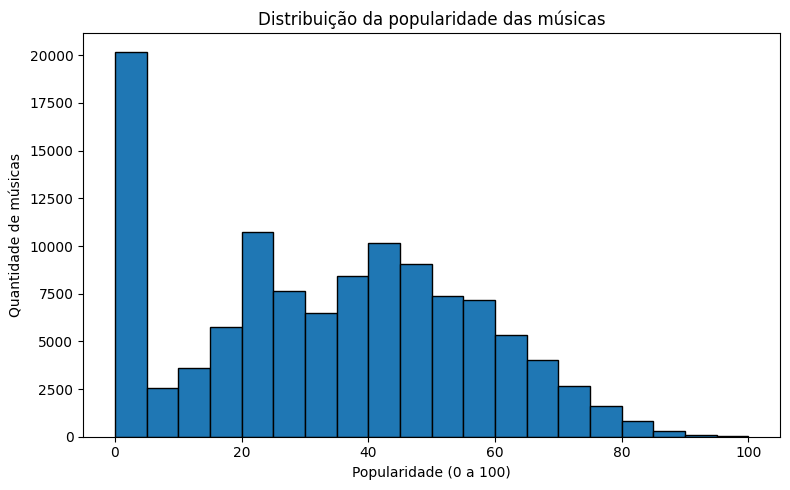

Média de popularidade: 33.24
Mediana de popularidade: 35.0


In [4]:
# Gráfico 1: distribuição da popularidade
plt.figure(figsize=(8, 5))
plt.hist(df[col_pop], bins=20, edgecolor="black")
plt.title("Distribuição da popularidade das músicas")
plt.xlabel("Popularidade (0 a 100)")
plt.ylabel("Quantidade de músicas")
plt.tight_layout()
plt.show()

print("Média de popularidade:", round(df[col_pop].mean(), 2))
print("Mediana de popularidade:", round(df[col_pop].median(), 2))

In [ ]:
# Gráfico 2: popularidade versus dançabilidade
plt.figure(figsize=(8, 5))
plt.scatter(df[col_dance], df[col_pop], alpha=0.25)
plt.title("Popularidade e dançabilidade")
plt.xlabel("Dançabilidade (0 a 1)")
plt.ylabel("Popularidade (0 a 100)")
plt.tight_layout()
plt.show()

In [ ]:
# Gráfico 3: popularidade versus energia
plt.figure(figsize=(8, 5))
plt.scatter(df[col_energy], df[col_pop], alpha=0.25)
plt.title("Popularidade e energia")
plt.xlabel("Energia (0 a 1)")
plt.ylabel("Popularidade (0 a 100)")
plt.tight_layout()
plt.show()

In [ ]:
# Gráfico 4: matriz de correlação
colunas_analise = [col_pop, col_dance, col_energy, col_valence, "duracao_minutos"]
nomes_legiveis = {
    col_pop: "Popularidade",
    col_dance: "Dançabilidade",
    col_energy: "Energia",
    col_valence: "Valência",
    "duracao_minutos": "Duração (min)"
}
correlacoes = df[colunas_analise].rename(columns=nomes_legiveis).corr()

plt.figure(figsize=(8, 6))
plt.imshow(correlacoes, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Correlação")
plt.xticks(range(len(correlacoes.columns)), correlacoes.columns, rotation=35, ha="right")
plt.yticks(range(len(correlacoes.index)), correlacoes.index)
plt.title("Correlação entre popularidade e características musicais")
for i in range(len(correlacoes.index)):
    for j in range(len(correlacoes.columns)):
        plt.text(j, i, f"{correlacoes.iloc[i, j]:.2f}", ha="center", va="center")
plt.tight_layout()
plt.show()

display(correlacoes.round(3))

## 6. Resultados e conclusões

A célula seguinte resume os resultados encontrados nesta execução. Use os valores calculados para escrever uma conclusão coerente com os gráficos; não presuma que uma correlação seja uma relação de causa e efeito.

In [6]:
# Resultados e conclusões

# Recalcula a matriz de correlação para garantir que ela exista
colunas_analise = [
    col_pop,
    col_dance,
    col_energy,
    col_valence,
    "duracao_minutos"
]

nomes_legiveis = {
    col_pop: "Popularidade",
    col_dance: "Dançabilidade",
    col_energy: "Energia",
    col_valence: "Valência",
    "duracao_minutos": "Duração (min)"
}

correlacoes = (
    df[colunas_analise]
    .rename(columns=nomes_legiveis)
    .corr(numeric_only=True)
)

corr_pop = (
    correlacoes["Popularidade"]
    .drop("Popularidade")
    .sort_values(key=lambda serie: serie.abs(), ascending=False)
)

print("Correlação com a popularidade:")
display(corr_pop.to_frame("Correlação").round(3))

mais_relacionada = corr_pop.index[0]
valor_corr = corr_pop.iloc[0]

if abs(valor_corr) < 0.10:
    interpretacao = "muito fraca"
elif abs(valor_corr) < 0.30:
    interpretacao = "fraca"
elif abs(valor_corr) < 0.50:
    interpretacao = "moderada"
else:
    interpretacao = "relativamente forte"

print("\nCONCLUSÃO AUTOMÁTICA")
print(
    f"A característica com maior correlação absoluta com a popularidade "
    f"foi {mais_relacionada}, com correlação de {valor_corr:.3f}. "
    f"A relação linear observada é {interpretacao}."
)

print(f"Popularidade média: {df[col_pop].mean():.2f}")
print(f"Popularidade mediana: {df[col_pop].median():.2f}")
print(f"Duração média: {df['duracao_minutos'].mean():.2f} minutos")

print(
    "\nConclusão geral: os resultados mostram associações entre as "
    "características musicais e a popularidade nesta base. A popularidade "
    "também pode depender de fatores como artista, divulgação, playlists "
    "e época de lançamento. Portanto, correlação não significa causalidade."
)

Correlação com a popularidade:


,Correlação
Valência,-0.041
Dançabilidade,0.035
Duração (min),-0.007
Energia,0.001



CONCLUSÃO AUTOMÁTICA
A característica com maior correlação absoluta com a popularidade foi Valência, com correlação de -0.041. A relação linear observada é muito fraca.
Popularidade média: 33.24
Popularidade mediana: 35.00
Duração média: 3.80 minutos

Conclusão geral: os resultados mostram associações entre as características musicais e a popularidade nesta base. A popularidade também pode depender de fatores como artista, divulgação, playlists e época de lançamento. Portanto, correlação não significa causalidade.


## 7. Considerações finais

O projeto aplicou etapas básicas de análise de dados com Python: carregamento, exploração, limpeza, visualização e interpretação. As conclusões devem ser apresentadas com base nos valores e gráficos gerados após a execução do notebook.

**Limitações:** a base é um recorte de dados e pode não representar todas as músicas ou todos os ouvintes do Spotify. A pontuação de popularidade pode mudar com o tempo e não equivale necessariamente ao número total de reproduções.

## 8. Fonte e entrega

- **Dataset:** [Spotify Tracks Dataset — Kaggle](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset)
- **Notebook:** depois de abrir este arquivo no Google Colab, execute as células em ordem, faça upload do CSV do Kaggle e salve uma cópia no seu Google Drive. Para entregar um link, clique em **Compartilhar** no Colab e ajuste o acesso conforme as orientações do professor.

**Importante:** este notebook é um modelo de trabalho completo, mas os gráficos e números só ficam preenchidos depois que você executar as células com o CSV real. Não entregue resultados que não tenham sido executados e conferidos.